In [2]:
!pip install -q nilearn nibabel

from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from nilearn import plotting, image
from pathlib import Path
import gc

DRIVE    = Path('/content/drive/MyDrive/Brain_alignment')
DATA     = DRIVE / 'lpp_data'
ANNOT    = DATA  / 'annotation/EN'
SAVE     = DRIVE / 'results'
SAVE.mkdir(exist_ok=True)

CONTEXT_SIZES = [1, 5, 20, 50, 100, -1]
RUNS          = [15, 16, 17, 18]
TR            = 2.0

print("Paths OK:", DATA.exists())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Paths OK: True


In [6]:
# Load existing R² map (sub-EN057) 
r2_data = np.load(SAVE / 'r2_scores_4runs.npz')
print("Keys:", list(r2_data.keys()))

key_map = {1: 'ctx_1', 5: 'ctx_5', 20: 'ctx_20', 50: 'ctx_50',
           100: 'ctx_100', -1: 'ctx_full'}

r2_matrix = np.stack([r2_data[key_map[ctx]] for ctx in CONTEXT_SIZES], axis=1)
print(f"R² matrix shape: {r2_matrix.shape}")

Keys: ['mask', 'ctx_1', 'ctx_5', 'ctx_20', 'ctx_50', 'ctx_100', 'ctx_full']
R² matrix shape: (129385, 6)


In [10]:
# Compute saturation map
# For each voxel: find context size at which R² is maximised
# Only consider voxels with positive R² in at least one condition

mask     = r2_data['mask'].astype(bool)   # (64*64*33,) or (64,64,33)
mask_1d  = mask.flatten()
n_voxels = mask_1d.sum()
print(f"Mask: {mask_1d.sum()} voxels out of {mask_1d.size}")

# r2_matrix rows correspond to masked voxels only
# Already built as (n_masked_voxels, 6) — confirm
print(f"R² matrix shape: {r2_matrix.shape}")  # should be (n_voxels, 6)

max_r2    = r2_matrix.max(axis=1)
valid_mask = max_r2 > 0

sat_idx         = np.argmax(r2_matrix, axis=1)
sat_ctx         = np.array([CONTEXT_SIZES[i] for i in sat_idx])
sat_ctx[~valid_mask] = 0
sat_ctx_display = sat_ctx.astype(float)
sat_ctx_display[sat_ctx == -1] = 200.0

print(f"Valid voxels: {valid_mask.sum()} ({100*valid_mask.mean():.1f}%)")
for ctx, label in zip(CONTEXT_SIZES, ['1','5','20','50','100','full']):
    val = 200.0 if ctx == -1 else float(ctx)
    n   = (sat_ctx_display[valid_mask] == val).sum()
    print(f"  ctx={label:>4}: {n} voxels ({100*n/valid_mask.sum():.1f}%)")

Mask: 129385 voxels out of 135168
R² matrix shape: (129385, 6)
Valid voxels: 97 (0.1%)
  ctx=   1: 6 voxels (6.2%)
  ctx=   5: 4 voxels (4.1%)
  ctx=  20: 5 voxels (5.2%)
  ctx=  50: 3 voxels (3.1%)
  ctx= 100: 3 voxels (3.1%)
  ctx=full: 76 voxels (78.4%)


In [11]:
# Reconstruct 3D saturation volume
BOLD_REF  = DATA / 'sub-EN057/func/sub-EN057_task-lppEN_run-15_echo-1_bold.nii.gz'
img_ref   = nib.load(str(BOLD_REF))
vol_shape = img_ref.shape[:3]
affine    = img_ref.affine

# Unpack into full volume
sat_vol_full        = np.zeros(mask_1d.size)
sat_vol_full[mask_1d] = sat_ctx_display
sat_vol  = sat_vol_full.reshape(vol_shape)
sat_img  = nib.Nifti1Image(sat_vol, affine)
nib.save(sat_img, str(SAVE / 'saturation_map_EN057.nii.gz'))

r2_max_full        = np.zeros(mask_1d.size)
r2_max_full[mask_1d] = max_r2
r2_max_img = nib.Nifti1Image(r2_max_full.reshape(vol_shape), affine)

print("Saved saturation_map_EN057.nii.gz")

Saved saturation_map_EN057.nii.gz


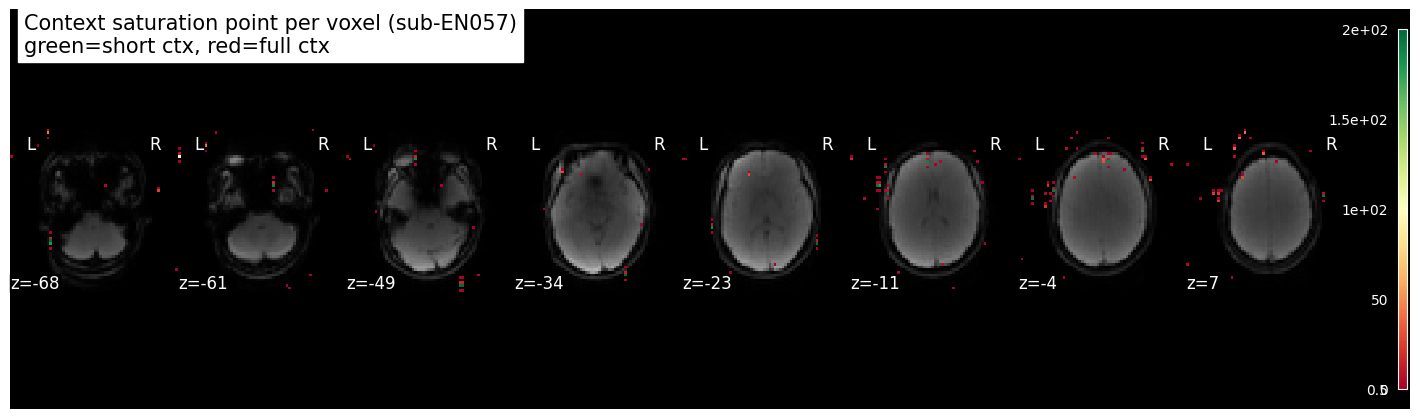

Saved saturation_map.png


In [12]:
# Plot saturation map 
mean_bold = image.mean_img(str(BOLD_REF))

fig = plt.figure(figsize=(14, 4))
display = plotting.plot_stat_map(
    sat_img,
    bg_img=mean_bold,
    threshold=0.5,
    cmap='RdYlGn',
    colorbar=True,
    title='Context saturation point per voxel (sub-EN057)\n'
          'green=short ctx, red=full ctx',
    display_mode='z',
    cut_coords=8,
    figure=fig
)
plt.savefig(SAVE / 'saturation_map.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved saturation_map.png")

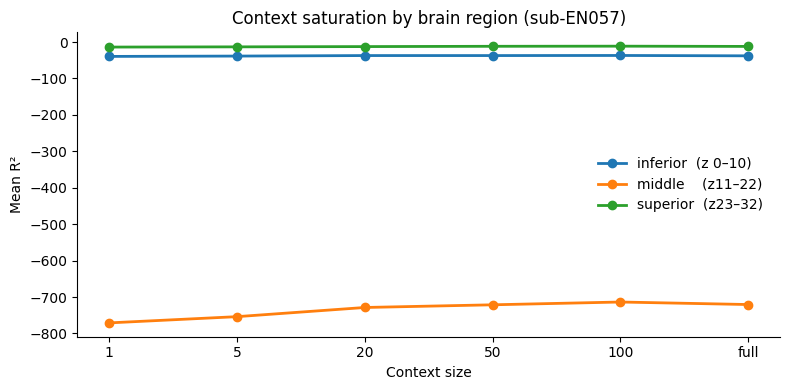

In [14]:
# 
ctx_labels = ['1', '5', '20', '50', '100', 'full']
fig, ax    = plt.subplots(figsize=(8, 4))
z_splits = {
    'inferior  (z 0–10) ': (0,  11),
    'middle    (z11–22) ': (11, 23),
    'superior  (z23–32) ': (23, 33),
}
for region, (z0, z1) in z_splits.items():
    mask_3d = np.zeros(vol_shape, dtype=bool)
    mask_3d[:, :, z0:z1] = True
    # intersect region mask with brain mask
    region_mask = mask_3d.flatten()[mask_1d]   # subset to masked voxels
    means = r2_matrix[region_mask].mean(axis=0)
    ax.plot(ctx_labels, means, 'o-', linewidth=2, label=region)

ax.set_xlabel('Context size')
ax.set_ylabel('Mean R²')
ax.set_title('Context saturation by brain region (sub-EN057)')
ax.legend(frameon=False)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'saturation_by_region.png', dpi=150, bbox_inches='tight')
plt.show()